# Plan 16: Diagonal LFU

Can matched-input Fisher updates improve rare-digit acquisition while preserving 0--8 recognition, and at what measured cost?

**Completed snapshot.** Study `production_v3`; sealed scientific snapshot. All evidence is exploratory. Opening this notebook requires no execution. It never trains, runs inference, downloads data, or repairs artifacts.

## Progress

| Item | Recorded state |
| --- | --- |
| Phase / status | 4: closeout / completed |
| Retained-method paired blocks completed / planned | 12 / 12 |
| Complete trajectories (operational / sealed) | 51 / 51 |
| All trajectories planned | 51 |
| Fresh trajectories completed / planned | 36 / 36 |
| Complete fresh FD / analytic pairs | 12 / 12 |
| Sealed incomplete trajectories | 0 |
| Active unit / checkpoint | none (completed) / step 1312/1312 |
| Accepted incoming-batch step / total_steps | 1312/1312 |
| Cumulative active / allocated hours | 2.42 / 20.00 |
| Allocation hours remaining | 17.58 |
| Remaining forecast hours | 0.00 |
| Heartbeat / revision | 2026-11-01T19:17:05.708816+00:00 / plan16-diagonal-lfu-v1/production_v3 |
| Storage used / ceiling / headroom (GB) | 0.61 / 500.00 / 499.39 |
| Filesystem free (GB) | 585.10 |

Progress is operational telemetry, not a process-liveness check. Scientific plots use only the sealed snapshot; no live metric files are scanned. Counts describe sealed rows, not unsealed work.

## Glossary And Settings

**Diagonal EWC** constrains the learner with diagonal Fisher curvature plus a separately recorded ridge. **LFU** tracks curvature along the learner's already-realized displacement. **Paired FD** differences model-label-integrated diagonals at two parameters using identical inputs; it is not Plan 15's FD KL. **EMA** is the common learning control. All treatments track the same likelihood Fisher.

The learner has 487 trainable coordinates, with diagonal EWC and isotropic ridge only: no STM, replay training, or FD-KL penalty. The fixed action $c$ weights fresh Fisher observations and the learning objective; ridge is $\kappa_t=r\,\mathrm{mean}(\widehat d_t)$.

**9 acquisition accuracy (recall)** conditions on true 9s. **0--8 retention accuracy** is the mean of the nine within-class accuracies, not overall mixture accuracy. **9 precision** conditions on predicted 9s and is standardized to evaluation prevalence 0.1; FPR uses the configured non-9 frequencies. Undefined precision remains a gap. Frozen initialization is inference-only context.

All plotted accuracies use an independent stratified holdout (200 images per class), never training batches or Fisher-reference inputs. Development and fresh holdouts are separate. Predictive NLL excludes every regularizer.

A **step** is one incoming batch. The saved `arrivals` field counts **online digits observed** (`step * samples_per_step`), excluding initialization. Cost per online digit uses that observation count, not the number of batches.

| Kind | Stage | Schedule / revision | Common setting / change | Evidence / validation |
| --- | --- | --- | --- | --- |
| Setting | development | main | c=0.01; ridge=0.1 | 6 complete; 0 incomplete |
| Setting | development | main | c=0.025; ridge=0.1 | 4 complete; 0 incomplete |
| Setting | development | main | c=0.05; ridge=0.1 | 2 complete; 0 incomplete |
| Setting | development | stationary | c=0.01; ridge=0.1 | 3 complete; 0 incomplete |
| Setting | fresh | main | c=0.01; ridge=0.1 | 24 complete; 0 incomplete |
| Setting | fresh | stationary | c=0.01; ridge=0.1 | 12 complete; 0 incomplete |
| Selected setting | development only | not an efficacy gate | c=0.01; ridge=0.1 | Frozen: 2026-11-01T17:38:30.693868+00:00 |
| Fresh allocation | frozen cohort | main=8; stationary=4 | EMA, Paired FD, Analytic LFU | 36 trajectories |
| Cost forecast | before fresh outcomes | whole fresh allocation | 1.19 h | Contingency: 1.25 |
| Change | 2026-11-01 | production_v2 | Consume recorded initialization model/order seeds. | [Full event and validation](../cache/mnist_experiment/plan16/production_v3/report_snapshot.json) |
| Change | 2026-11-01 | production_v3 | Solve the same physical NLL plus EWC/ridge objective. | [Full event and validation](../cache/mnist_experiment/plan16/production_v3/report_snapshot.json) |

Recorded core settings: {"dtype": "float32", "fisher_dtype": "float64", "samples_per_step": 4}. Full resolved configuration, selection and all 2 changes remain in the linked compact snapshot; only brief opening summaries of the latest six events appear here. Development choices are not fresh evidence; different stages, schedules and settings are never pooled.

## Development

Complete development paths are descriptive, including explicitly unpaired arms. After selection, top panels show only the common c/ridge on the main schedule; before selection, all completed development curves are shown. All candidate settings remain in the lower trade-off/cost panels and settings table; stationary points are squares. Regime bands follow recorded segments. Lower points are whole-replica means. Axes count online digits; steps count incoming batches.

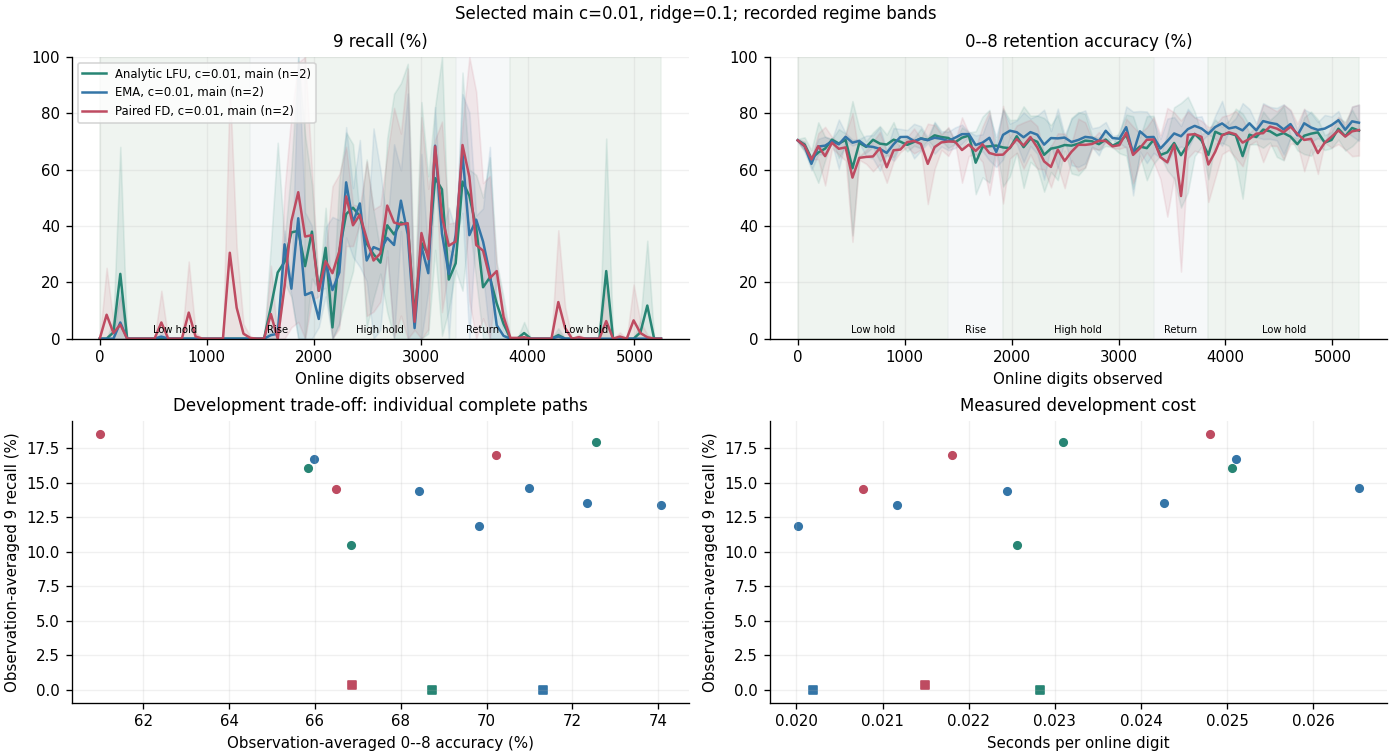

In [4]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/01_development.png'))

## Fresh Main Trajectories

Each row uses its own complete EMA/treatment cohort. Curves are means across replicas; bands are descriptive pointwise mean +/- 1.96 SE, not paired effect intervals. No band is drawn for a single pair. Regime shading follows the recorded segments. Frozen initialization is the dotted reference in the legend.

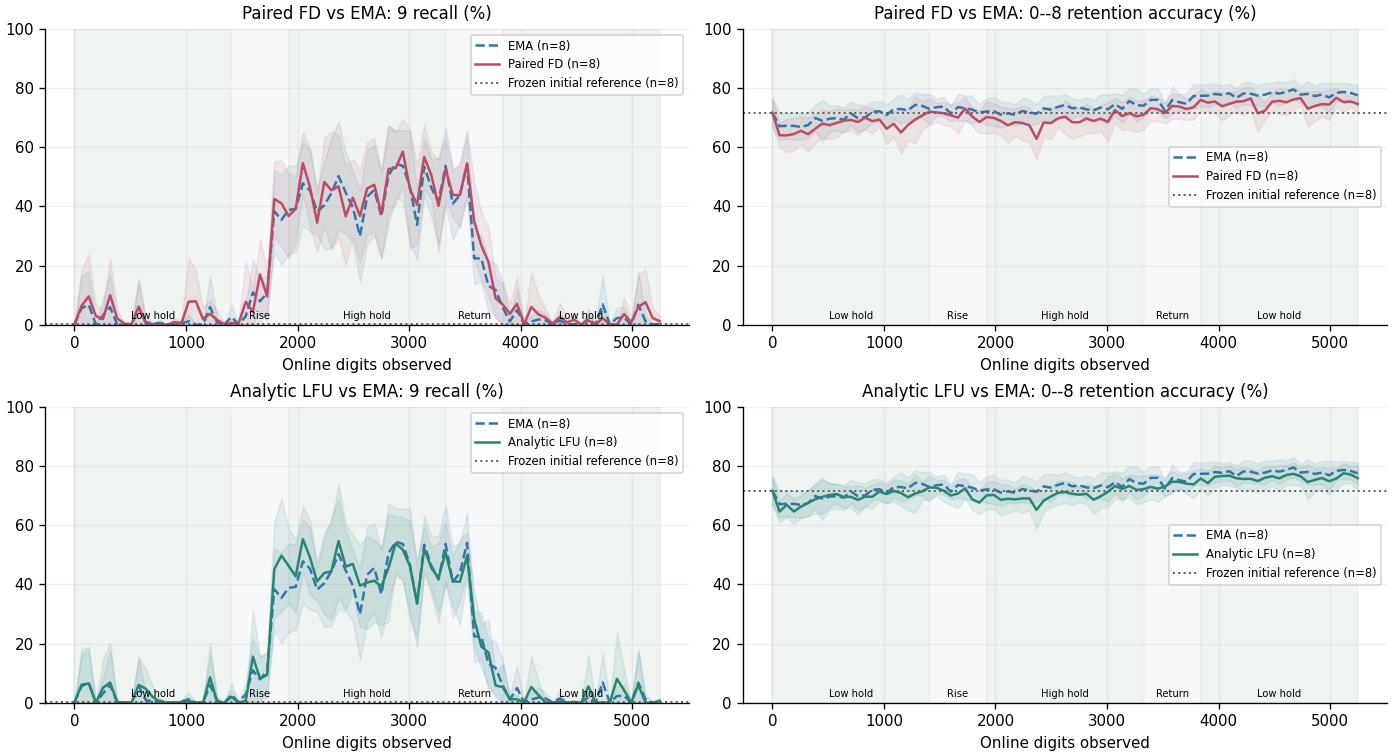

In [6]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/02_fresh_main.png'))

## Fresh Stationary Trajectories

Stationary controls are not pooled with the main schedule. The same complete-pair and band conventions apply.

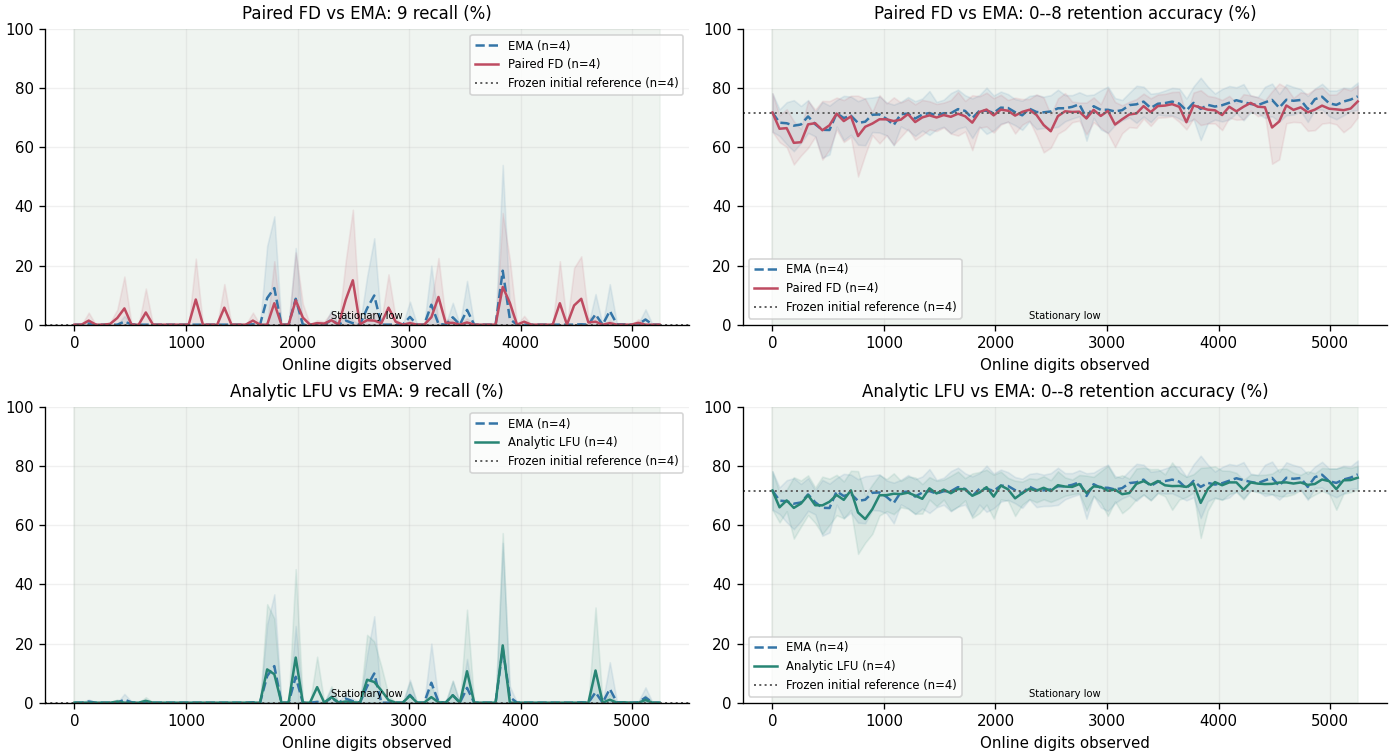

In [8]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/03_fresh_stationary.png'))

## Precision, Recall, And Exposure

Precision at evaluation prevalence 0.1 is undefined when there are no predicted positives. Gaps are not interpolated. Expected and observed exposure counts are cumulative online counts, not including initialization (reported in the exposure legend). A cohort precision point is shown only when every replica has defined precision; an empty path is labeled explicitly. FPR remains in the sealed snapshot; initialization class counts and unique-ID accounting are recorded in each `units/assets-<cohort>-rNNN/summary.json` under the study root.

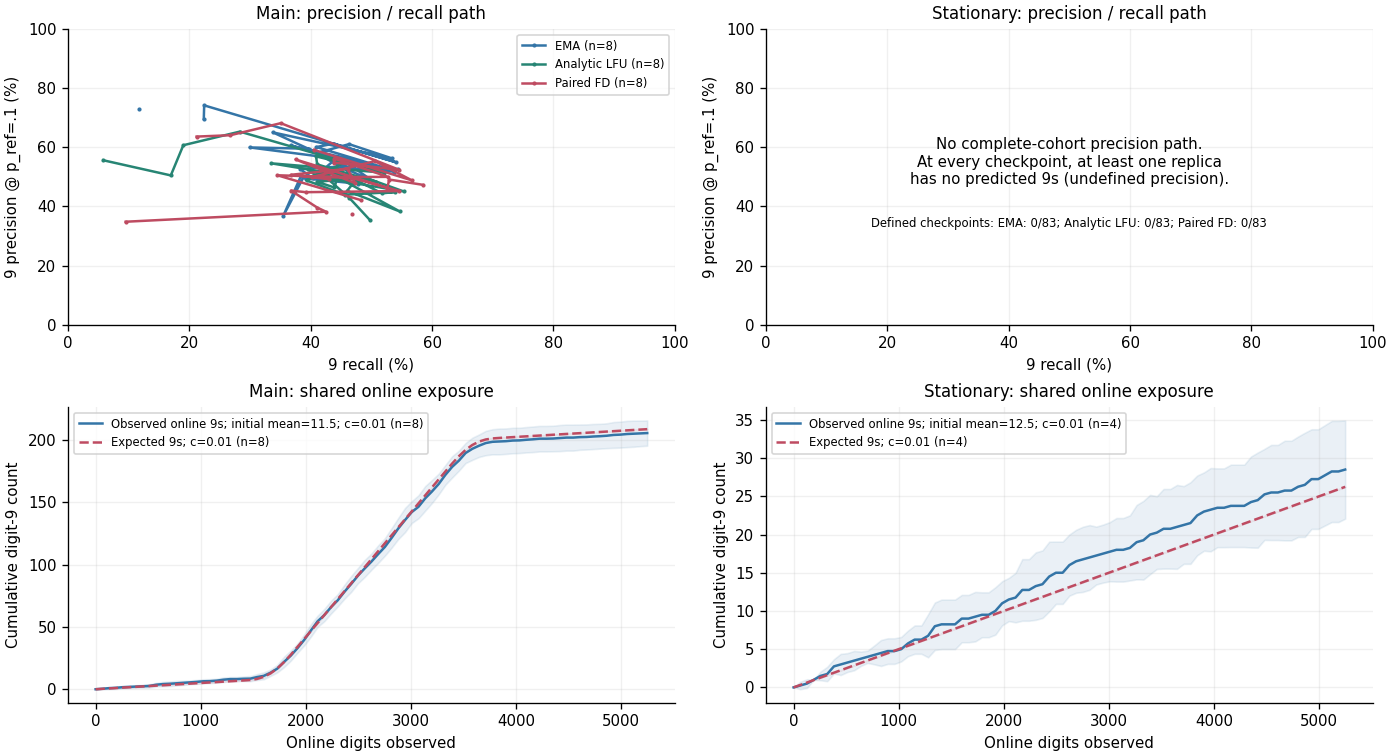

In [10]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/04_precision_exposure.png'))

## Paired Differences And Compute

Trapezoidal integration over recorded cumulative observations (arrivals), divided by the full observation span. Segment intervals belong to the segment of their right endpoint. Bootstrap draws: 2000; persisted seed: 161101. The resampling unit is a complete paired replica trajectory. Crosses show individual differences when fewer than four pairs exist. The lower-right panel shows main-schedule segment means only; method colors and metric markers identify every series.

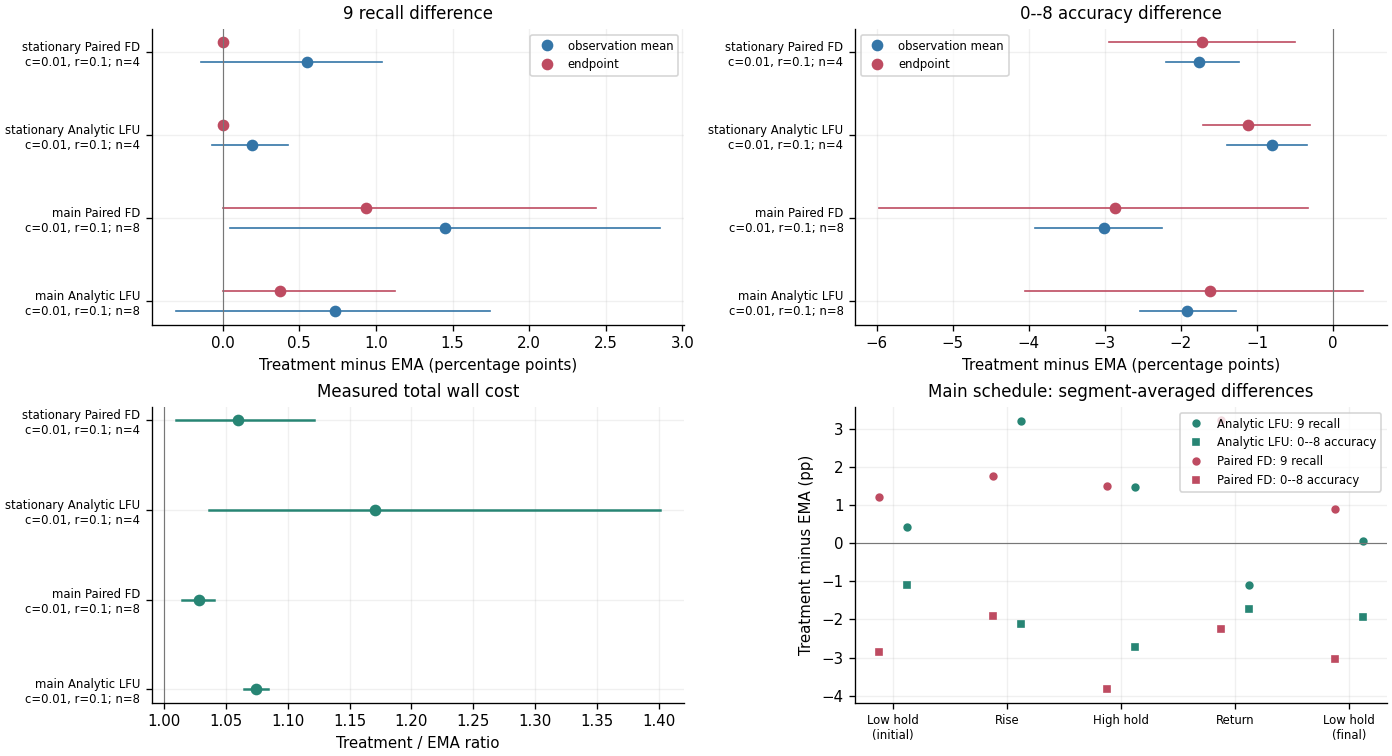

In [12]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/05_paired_cost.png'))

### Paired Summary

| Cohort / setting | Contrast | Complete pairs | Full-path 9 (pp, CI) | Full-path 0--8 (pp, CI) | Endpoint 9 / 0--8 (pp) | Wall ratio (CI) |
| --- | --- | --- | --- | --- | --- | --- |
| fresh / main / c=0.01, r=0.1 | Analytic LFU - EMA | 8 | 0.73 [-0.30, 1.75] | -1.92 [-2.54, -1.27] | 0.38 / -1.63 | 1.07 [1.06, 1.08] |
| fresh / main / c=0.01, r=0.1 | Paired FD - EMA | 8 | 1.45 [0.05, 2.85] | -3.02 [-3.92, -2.25] | 0.94 / -2.87 | 1.03 [1.01, 1.04] |
| fresh / stationary / c=0.01, r=0.1 | Analytic LFU - EMA | 4 | 0.19 [-0.07, 0.43] | -0.80 [-1.39, -0.34] | 0.00 / -1.12 | 1.17 [1.04, 1.40] |
| fresh / stationary / c=0.01, r=0.1 | Paired FD - EMA | 4 | 0.55 [-0.14, 1.04] | -1.76 [-2.20, -1.24] | 0.00 / -1.72 | 1.06 [1.01, 1.12] |

Nominal 95% percentile intervals resample complete replica pairs, not timepoints. They are unreliable below four pairs and absent for one; individual differences are plotted. Comparisons and interim looks are unadjusted. Exact differences, segment and endpoint intervals, costs, and unit IDs remain in analysis.json. This table shows fresh cohorts when available; development remains in the earlier figure and full analysis. Equal digit exposure is not equal compute.

## Supporting Numerical Health

Pre-clipping diagnostics cannot be hidden by PSD projection. After selection, one completed main path per method at the common setting is shown; before selection, all development settings are shown. These are supporting diagnostics, not efficacy gates. Full scalar diagnostics remain in the compact snapshot.

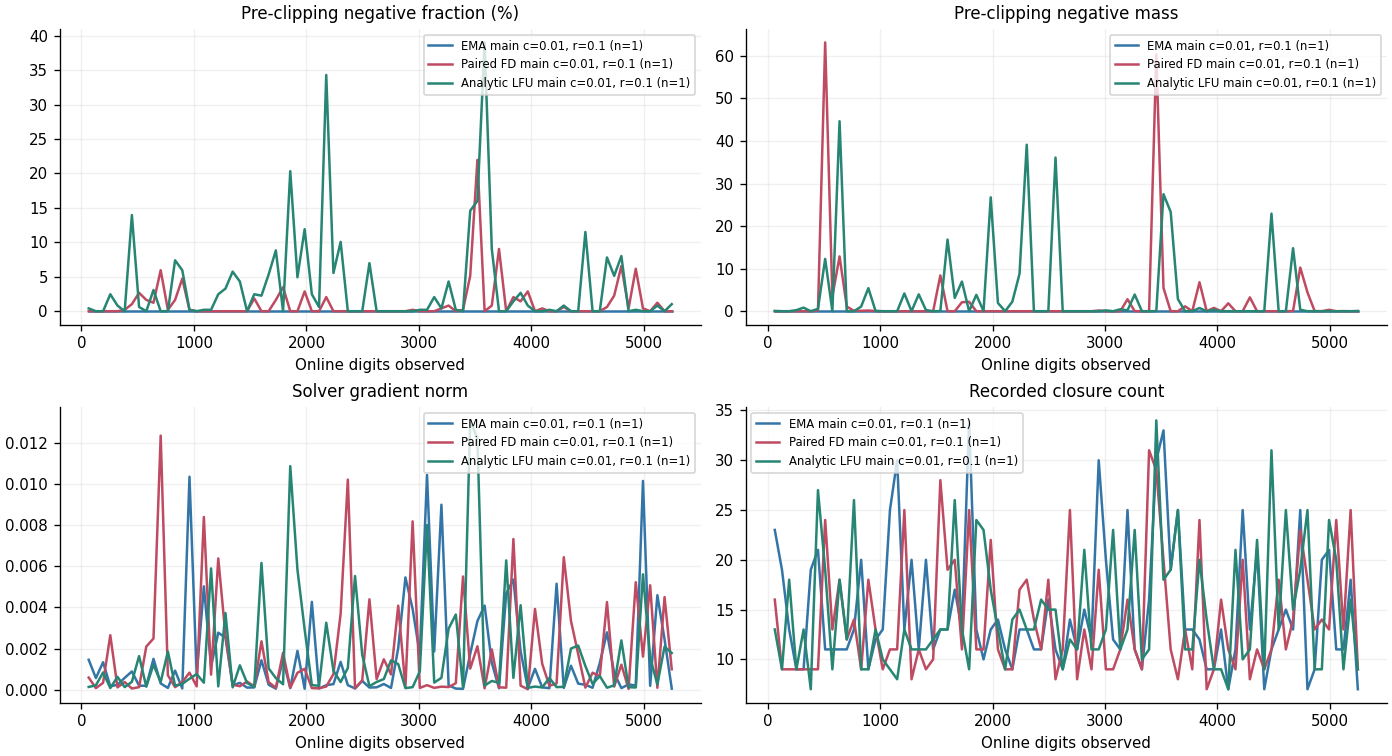

In [15]:
from IPython.display import Image, display
display(Image(filename='../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/06_health.png'))

## Conclusion

Fresh changing-mixture results versus EMA, using 8 complete paired replicas per method. Accuracy changes are observation-averaged over the full trajectory, in percentage points (pp).

| Method | 9 recall change (pp) | 0--8 retention change (pp) | Extra wall time |
| --- | --- | --- | --- |
| Paired FD | +1.45 [0.05, 2.85] | -3.02 [-3.92, -2.25] | 2.8% |
| Analytic LFU | +0.73 [-0.30, 1.75] | -1.92 [-2.54, -1.27] | 7.4% |

Brackets are exploratory, nominal 95% paired-bootstrap confidence intervals, unadjusted for multiple comparisons or interim inspection. Extra wall time is the mean paired runtime ratio minus one, expressed as a percentage; it is not an isolated Fisher-update benchmark.

**Changing mixture:** Analytic LFU (8 pairs): point estimates show higher 9 recall but lower 0--8 retention. Its nominal recall interval includes zero. Paired FD (8 pairs): point estimates show higher 9 recall but lower 0--8 retention.

**Stationary low prevalence:** Analytic LFU (4 pairs): point estimates show higher 9 recall but lower 0--8 retention. Its nominal recall interval includes zero. Paired FD (4 pairs): point estimates show higher 9 recall but lower 0--8 retention. Its nominal recall interval includes zero.

A recall gain with lower retention is a trade-off, not an improvement in both. See the paired summary for full-path effects, nominal intervals and measured overhead. Equal exposure is not equal compute or matched retention; these results alone do not establish sample savings. The final endpoint follows a return to rare 9s, so it is not a stand-alone acquisition score.

0 sealed incomplete trajectories; 0 unmatched fresh arms. Unpaired development-screen controls remain descriptive. No efficacy gate is applied.

Diagonal curvature is chart-dependent and omits off-diagonal information; matched current inputs remain a local input-sampling approximation. Clipping and finite-tolerance solves can affect behavior. This small, single-architecture study neither proves diagonal EWC sufficient nor rules out LFUs elsewhere; accuracy proxies do not establish separate visual domains.

Compact artifacts: [sealed snapshot](../cache/mnist_experiment/plan16/production_v3/report_snapshot.json), [paired analysis and diagnostics](../cache/mnist_experiment/plan16/production_v3/report/generation-abcda40616fcbde8dc57ce05/analysis.json). PNGs are embedded in executed display outputs and also stored in the report generation; moving the notebook does not lose its displayed figures.